<a href="https://colab.research.google.com/github/Siddhant-Gulecha/Siddhant_Gulecha_23BDS0253/blob/main/EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA Project
Dataset: Suicide in Rural and Urban China (`SuicideChina.csv`)


## 1. Data Loading

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

url = 'https://raw.githubusercontent.com/salemprakash/EDA/main/Data/SuicideChina.csv'
df = pd.read_csv(url)
print("Shape:", df.shape)
df.head(10)


Shape: (2571, 12)


,rownames,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method
0,1,1,yes,no,no,2010,12,female,39,Secondary,household,Other poison
1,2,2,no,yes,no,2009,3,male,83,primary,farming,Hanging
2,3,3,no,yes,no,2010,2,male,60,primary,farming,Hanging
3,4,4,no,yes,no,2011,1,male,73,primary,farming,Hanging
4,5,5,yes,no,no,2009,8,male,51,Secondary,farming,Pesticide
5,6,6,no,yes,no,2009,11,male,62,iliterate,farming,Pesticide
6,7,7,no,yes,no,2010,1,female,90,iliterate,farming,Pesticide
7,8,8,yes,no,no,2010,10,male,54,Secondary,farming,Pesticide
8,9,9,no,yes,no,2010,7,male,66,primary,farming,Hanging
9,10,10,yes,no,no,2011,1,female,30,Secondary,others/unknown,Poison unspec


## 2. Statistical Analysis

In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2571 entries, 0 to 2570
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   rownames      2571 non-null   int64 
 1   Person_ID     2571 non-null   int64 
 2   Hospitalised  2571 non-null   object
 3   Died          2571 non-null   object
 4   Urban         2571 non-null   object
 5   Year          2571 non-null   int64 
 6   Month         2571 non-null   int64 
 7   Sex           2571 non-null   object
 8   Age           2571 non-null   int64 
 9   Education     2571 non-null   object
 10  Occupation    2571 non-null   object
 11  method        2571 non-null   object
dtypes: int64(5), object(7)
memory usage: 241.2+ KB


In [7]:
df.describe()


,rownames,Person_ID,Year,Month,Age
count,2571.000000,2571.000000,2571.000000,2571.000000,2571.000000
mean,1286.000000,1286.000000,2010.045508,6.298327,52.630883
std,742.328095,742.328095,0.791412,3.202515,19.783878
min,1.000000,1.000000,2009.000000,1.000000,12.000000
25%,643.500000,643.500000,2009.000000,4.000000,37.000000
50%,1286.000000,1286.000000,2010.000000,6.000000,53.000000
75%,1928.500000,1928.500000,2011.000000,9.000000,69.000000
max,2571.000000,2571.000000,2011.000000,12.000000,100.000000


## 3. Missing Data & Cleaning

In [8]:
print("Explicit NAs:")
print(df.isnull().sum())


Explicit NAs:
rownames        0
Person_ID       0
Hospitalised    0
Died            0
Urban           0
Year            0
Month           0
Sex             0
Age             0
Education       0
Occupation      0
method          0
dtype: int64


In [9]:
for col in df.select_dtypes(include=['object']).columns:
    print(f"{col}: {set(df[col].unique())}\n")


Hospitalised: {'yes', 'no'}

Died: {'no', 'yes'}

Urban: {'no', 'unknown', 'yes'}

Sex: {'male', 'female'}

Education: {'iliterate', 'Secondary', 'primary', 'Tertiary', 'unknown'}

Occupation: {'business/service', 'worker', 'professional', 'student', 'retiree', 'others/unknown', 'others', 'household', 'unemployed', 'farming'}

method: {'Others', 'Cutting', 'Hanging', 'Poison unspec', 'Jumping', 'unspecified', 'Other poison', 'Drowning', 'Pesticide'}



In [10]:
if 'rownames' in df.columns:
    df = df.drop(columns=['rownames'])

df = df.drop_duplicates()

df['Urban'] = df['Urban'].replace('unknown', np.nan)
df['Education'] = df['Education'].replace('unknown', np.nan)
df['Occupation'] = df['Occupation'].replace('others/unknown', np.nan)
df['method'] = df['method'].replace('unspecified', np.nan)

print("NAs after replacing unknown values:")
print(df.isnull().sum())

for col in ['Urban', 'Education', 'Occupation', 'method']:
    df[col] = df[col].fillna('Unknown')


NAs after replacing unknown values:
Person_ID         0
Hospitalised      0
Died              0
Urban            81
Year              0
Month             0
Sex               0
Age               0
Education        80
Occupation      156
method           48
dtype: int64


## 4. Data Transformation

In [11]:
cat_cols = ['Hospitalised', 'Died', 'Urban', 'Sex', 'Education', 'Occupation', 'method']
for col in cat_cols:
    df[col] = df[col].astype('category')

df['Age_Group'] = pd.cut(df['Age'], bins=[0, 18, 35, 60, 120], labels=['<18', '18-35', '36-59', '60+'], right=False)

df['Season'] = df['Month'].map({
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
}).astype('category')

df['Outcome'] = np.where(df['Died'] == 'yes', 'Fatal', 'Non-Fatal')
df['Outcome'] = df['Outcome'].astype('category')

df.head()


,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method,Age_Group,Season,Outcome
0,1,yes,no,no,2010,12,female,39,Secondary,household,Other poison,36-59,Winter,Non-Fatal
1,2,no,yes,no,2009,3,male,83,primary,farming,Hanging,60+,Spring,Fatal
2,3,no,yes,no,2010,2,male,60,primary,farming,Hanging,60+,Winter,Fatal
3,4,no,yes,no,2011,1,male,73,primary,farming,Hanging,60+,Winter,Fatal
4,5,yes,no,no,2009,8,male,51,Secondary,farming,Pesticide,36-59,Summer,Non-Fatal


## 5. Univariate Analysis

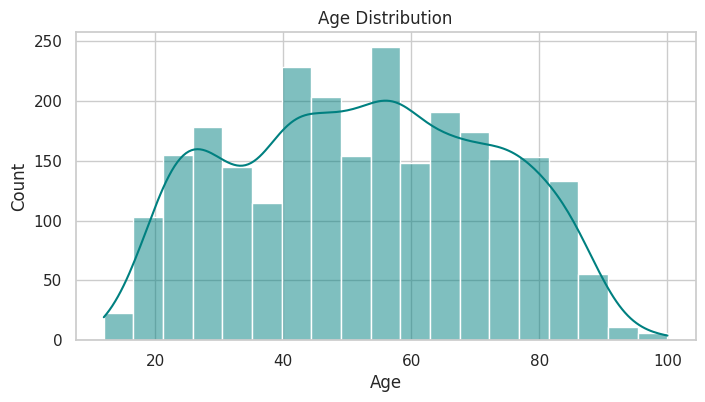

In [12]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'], kde=True, color='teal')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()


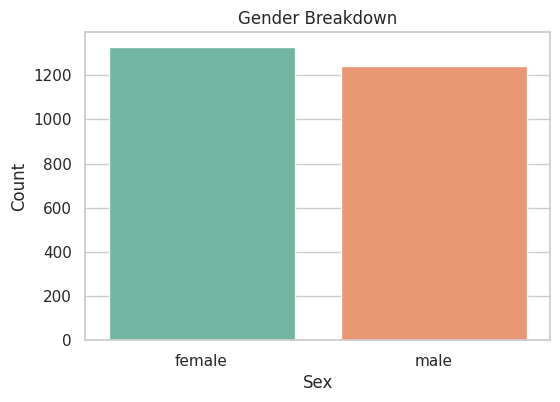

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex', palette='Set2', hue='Sex', legend=False)
plt.title('Gender Breakdown')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.show()


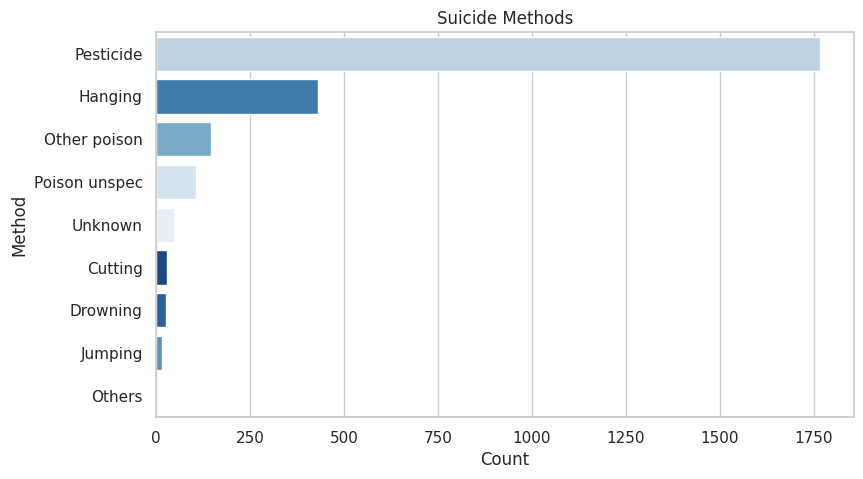

In [14]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, y='method', order=df['method'].value_counts().index, palette='Blues_r', hue='method', legend=False)
plt.title('Suicide Methods')
plt.xlabel('Count')
plt.ylabel('Method')
plt.show()


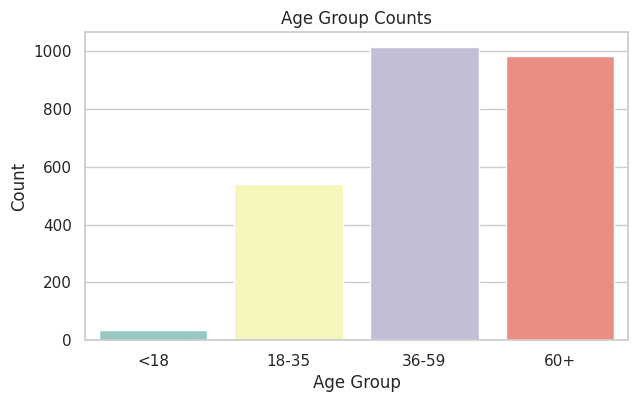

In [15]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Age_Group', palette='Set3', hue='Age_Group', legend=False)
plt.title('Age Group Counts')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.show()


## 6. Bivariate Analysis

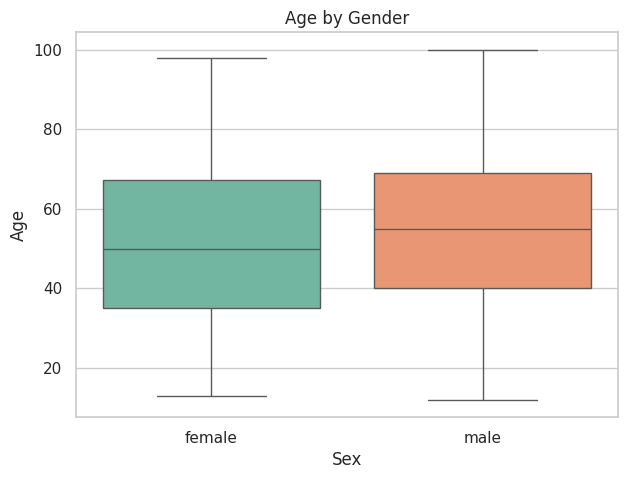

In [16]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Sex', y='Age', palette='Set2', hue='Sex', legend=False)
plt.title('Age by Gender')
plt.show()


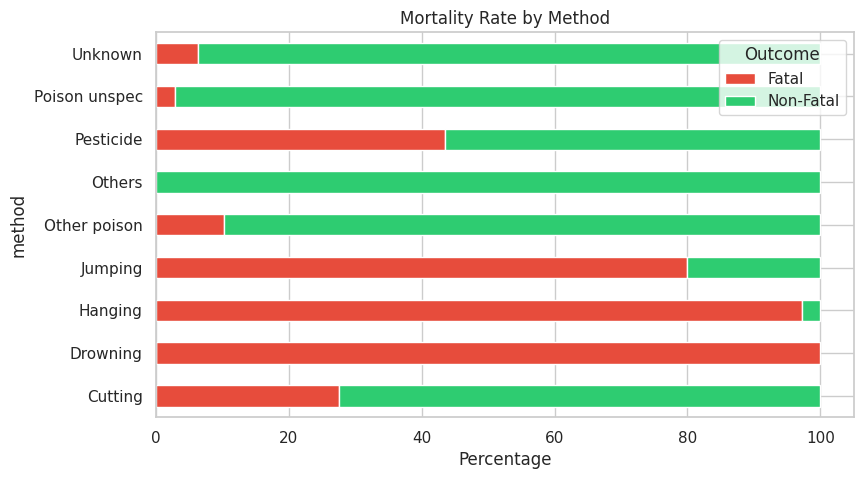

In [17]:
ct = pd.crosstab(df['method'], df['Outcome'], normalize='index') * 100
ct.plot(kind='barh', stacked=True, figsize=(9, 5), color=['#e74c3c', '#2ecc71'])
plt.title('Mortality Rate by Method')
plt.xlabel('Percentage')
plt.show()


<Figure size 900x400 with 0 Axes>

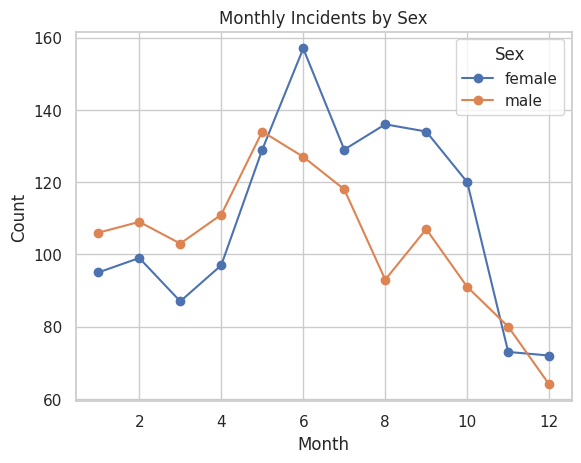

In [18]:
plt.figure(figsize=(9, 4))
df.groupby(['Month', 'Sex'], observed=False).size().unstack().plot(kind='line', marker='o')
plt.title('Monthly Incidents by Sex')
plt.xlabel('Month')
plt.ylabel('Count')
plt.show()


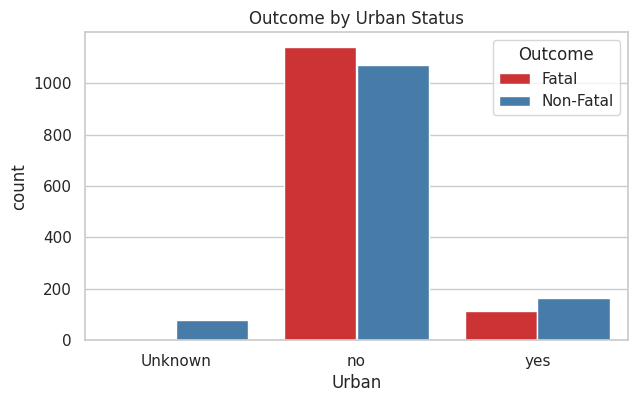

In [19]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Urban', hue='Outcome', palette='Set1')
plt.title('Outcome by Urban Status')
plt.show()


## 7. Multivariate Analysis

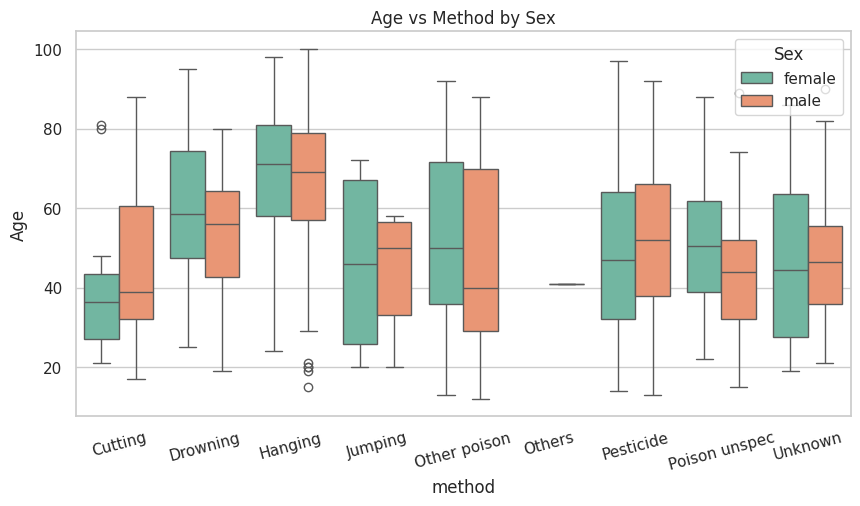

In [20]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='method', y='Age', hue='Sex', palette='Set2')
plt.title('Age vs Method by Sex')
plt.xticks(rotation=15)
plt.show()


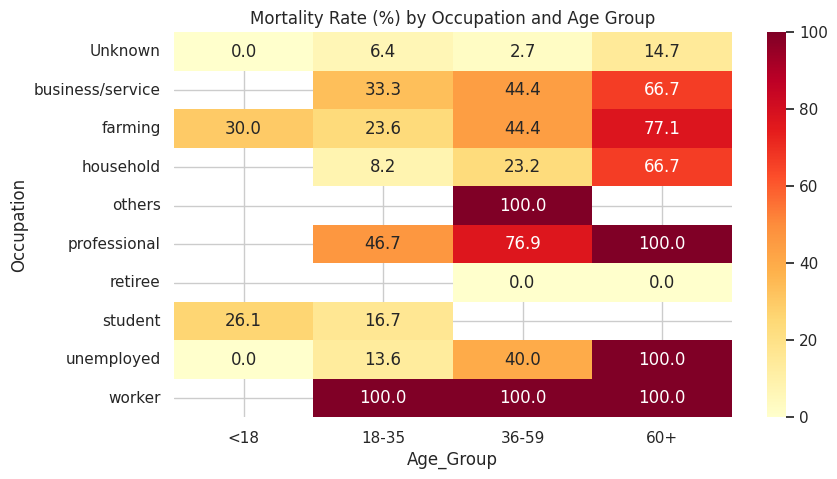

In [21]:
pivot = df.pivot_table(index='Occupation', columns='Age_Group', values='Died',
                       aggfunc=lambda x: (x == 'yes').mean() * 100, observed=False)
plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Mortality Rate (%) by Occupation and Age Group')
plt.show()


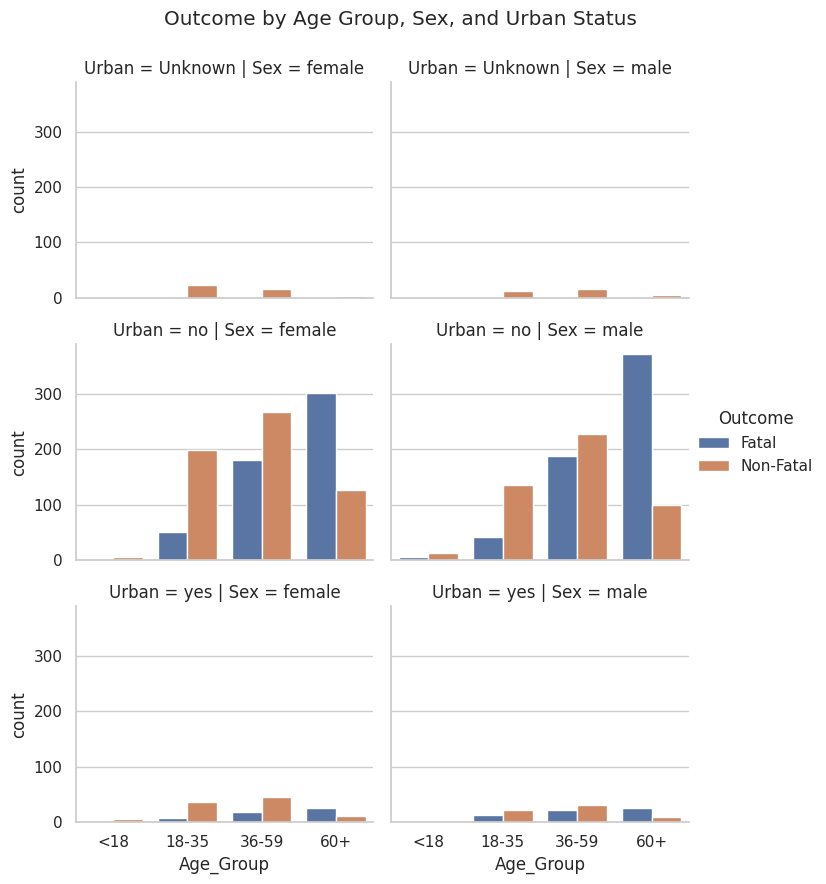

In [22]:
g = sns.catplot(data=df, x='Age_Group', hue='Outcome', col='Sex', row='Urban', kind='count', height=3, aspect=1.2)
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle('Outcome by Age Group, Sex, and Urban Status')
plt.show()


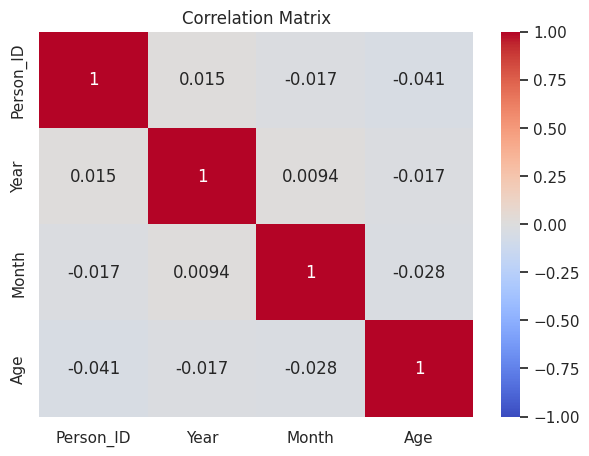

In [23]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()


## 8. Summary
- Most incidents occur in farming occupations and middle/older age groups.
- Pesticides and hanging are the most frequent and have higher mortality rates.
- Incident numbers peak in late spring and summer months.
